# Lab 3, Notebook B — Kernel ridge regression

*Linear Algebra for Data Science, UCU 2026. Uses Session 4.2 (kernels, the representer theorem, kernel ridge) and Session 4.1 (Cholesky).*

A kernel $k(\mathbf{x},\mathbf{y}) = \langle\phi(\mathbf{x}),\phi(\mathbf{y})\rangle$ is an inner product in a feature space $\mathcal{F}$ that you never construct. By the representer theorem, ridge regression in $\mathcal{F}$ has a solution $f(\mathbf{x}) = \sum_i\alpha_i k(\mathbf{x}_i,\mathbf{x})$ with

$$(K + \lambda I)\,\boldsymbol\alpha = \mathbf{y},\qquad K_{ij} = k(\mathbf{x}_i,\mathbf{x}_j).$$

$K+\lambda I$ is symmetric positive definite for every kernel and every $\lambda>0$, so one Cholesky factorization solves the problem. The cost depends on $n$, not on $\dim\mathcal{F}$. In this notebook you check the kernel trick, see what $\lambda$ does to the conditioning, and measure the cost.

**How to work.** As in Notebook A: **predict in writing, then compute, then explain any difference.**

**Rules.**
- Inside the functions you implement, do not call `np.linalg.inv` or `sklearn`'s `KernelRidge`. Use `KernelRidge` and `GaussianProcessRegressor` only where a cell says **check**.
- You may use `scipy.linalg.cholesky`, `cho_factor`/`cho_solve`, `solve_triangular` and `np.linalg.eigvalsh`.
- Do not change the seeds.
- Before you submit, run `Kernel → Restart & Run All`.

**Marking.** Core B is worth 2 points at the defence; the code point and the extension are shared with Notebook A.

**Contents.** B1 The solver · B2 The kernel trick, checked · B3 The Gaussian kernel and the role of $\lambda$ · B4 Cost and scale · Extension E3 (GP regression). Attempt **at most one** extension in the whole lab.

| | |
|---|---|
| **Team member 1** | *Mariia Cherkasova* |
| **Team member 2** | *Andrii Polishko* |
| **Extension attempted** (at most one in the whole lab) | *E3* |
| **Late days used on this lab** | *3* |
| **Runs top to bottom from a clean kernel** | *yes* |

In [74]:
import sys, time
from math import comb
import numpy as np
import scipy, scipy.linalg as sl
import matplotlib, matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_friedman1
from sklearn.preprocessing import PolynomialFeatures

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| sklearn", sklearn.__version__)

python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | matplotlib 3.10.0 | sklearn 1.6.1


**Data.** Friedman's benchmark #1: ten features uniform on $[0,1]$, of which only five matter, through
$y = 10\sin(\pi x_1x_2) + 20(x_3-\tfrac12)^2 + 10x_4 + 5x_5 + \text{noise}$, with noise standard deviation 1. It is synthetic, but nonlinear in a way a linear model cannot capture, which is the point of a kernel.

We split 1000 points into 500 for training, 250 for validation and 250 for testing. We standardise the features with **training** statistics only, and centre $y$ by its training mean: kernel ridge has no intercept, so predictions are of the centred $y$ (add the mean back to report them in the original units).

In [75]:
X_all, y_all = make_friedman1(n_samples=1000, noise=1.0, random_state=0)
mu_x, sd_x = X_all[:500].mean(axis=0), X_all[:500].std(axis=0)
X_all = (X_all - mu_x) / sd_x
y_mean = y_all[:500].mean()
Xtr, Xva, Xte = X_all[:500], X_all[500:750], X_all[750:]
ytr, yva, yte = y_all[:500] - y_mean, y_all[500:750] - y_mean, y_all[750:] - y_mean
print(Xtr.shape, Xva.shape, Xte.shape)

def mse(a, b):
    return np.mean((a - b) ** 2)

(500, 10) (250, 10) (250, 10)


---
## B1. The solver

Implement:
- `k_poly(X, Y, d, c)`, the matrix of $(c + \mathbf{x}^\top\mathbf{y})^d$ over the rows of `X` and `Y`;
- `k_gauss(X, Y, sigma)`, the matrix of $\exp(-\|\mathbf{x}-\mathbf{y}\|^2/(2\sigma^2))$. Use $\|\mathbf{x}-\mathbf{y}\|^2 = \|\mathbf{x}\|^2+\|\mathbf{y}\|^2-2\mathbf{x}^\top\mathbf{y}$, with no Python loops over points, and clip tiny negative values caused by rounding to zero;
- `krr_fit(K, y, lam)`, which returns $\boldsymbol\alpha$ solving $(K+\lambda I)\boldsymbol\alpha = \mathbf{y}$ by one Cholesky factorization, leaving `K` unchanged;
- `krr_predict(K_test_train, alpha)`.

In [76]:
def k_poly(X, Y, d, c):
    # YOUR CODE HERE
    return (c + X @ Y.T)**d

def k_gauss(X, Y, sigma):
    # YOUR CODE HERE
    X_sq = (X ** 2).sum(axis=1)
    Y_sq = (Y ** 2).sum(axis=1)
    d = X_sq[:, None] + Y_sq[None, :] - 2 * X @ Y.T
    d = np.maximum(d, 0)
    divide = -d / (2 * sigma ** 2)
    return np.exp(divide)

def krr_fit(K, y, lam):
    # YOUR CODE HERE
    A = K + lam * np.eye(len(K))
    factor = sl.cho_factor(A, lower=True)
    alpha = sl.cho_solve(factor, y)
    return alpha

def krr_predict(K_test_train, alpha):
    # YOUR CODE HERE
    result = []
    for i in range(len(K_test_train)):
      pred = (K_test_train[i, :] * alpha).sum()
      result.append(pred)
    return np.array(result)


In [77]:
# check against scikit-learn on 200 training points (sklearn calls lam 'alpha', and uses gamma = 1/(2 sigma^2))
from sklearn.kernel_ridge import KernelRidge
sigma, lam = 4.0, 0.1
a = krr_fit(k_gauss(Xtr[:200], Xtr[:200], sigma), ytr[:200], lam)
mine = krr_predict(k_gauss(Xva, Xtr[:200], sigma), a)
ref = KernelRidge(alpha=lam, kernel="rbf", gamma=1 / (2 * sigma ** 2)).fit(Xtr[:200], ytr[:200]).predict(Xva)
print("max difference from sklearn:", np.abs(mine - ref).max())
assert np.allclose(mine, ref)

max difference from sklearn: 1.3855583347321954e-13


---
## B2. The kernel trick, checked

**(a)** For the polynomial kernel $(1+\mathbf{x}^\top\mathbf{y})^2$ on $\mathbb{R}^{10}$, write the explicit feature map `phi_poly2(X)` with $\phi(\mathbf{x})^\top\phi(\mathbf{y}) = (1+\mathbf{x}^\top\mathbf{y})^2$. Expand the square to find the entries, minding the $\sqrt2$ factors. How many features are there? Check against `k_poly`.

In [78]:
def phi_poly2(X):
    # YOUR CODE HERE
    n = X.shape[0]
    const = np.ones((n, 1))
    b = np.sqrt(2) * X
    square = X ** 2
    i, j = np.triu_indices(X.shape[1], k=1)
    cross = np.sqrt(2) * X[:, i] * X[:, j]
    return np.hstack([const, b, square, cross])

Phi_tr, Phi_te = phi_poly2(Xtr), phi_poly2(Xte)
print("dim F =", Phi_tr.shape[1])
# check
assert np.allclose(Phi_tr[:50] @ Phi_te[:40].T, k_poly(Xtr[:50], Xte[:40], 2, 1))

dim F = 66


**Your answer.** Expanding $(1+\mathbf{x}^\top\mathbf{y})^2$ gives $\phi(\mathbf{x}) = (1,\ \sqrt2\,x_i,\ x_i^2,\ \sqrt2\,x_ix_j\ (i<j))$. The $\sqrt2$ comes from the factor 2 on the linear and cross terms, split between $\phi(\mathbf{x})$ and $\phi(\mathbf{y})$. That's $1 + 10 + 10 + 45 = 66$ features, and the check against `k_poly` passes.

**(b)** Fit ordinary ridge regression on the features: $\mathbf{w}$ solving $(\Phi^\top\Phi+\lambda I)\mathbf{w} = \Phi^\top\mathbf{y}$, by Cholesky, with **no separate intercept** and $\lambda = 1$. Compare its test predictions $\Phi_{\text{test}}\mathbf{w}$ with kernel ridge using `k_poly(·,·,2,1)` and the same $\lambda$. Explain why they agree, citing the representer theorem.

In [79]:
lam = 1.0
# YOUR CODE HERE

# feature route
Phi_tr = phi_poly2(Xtr)
Phi_te = phi_poly2(Xte)
G = Phi_tr.T @ Phi_tr + lam * np.eye(66)
r_v = Phi_tr.T @ ytr
w = sl.cho_solve(sl.cho_factor(G, lower=True), r_v)
pred_feat = Phi_te @ w

# kernel route
krr_tr = k_poly(Xtr, Xtr, 2, 1)
alpha_k = krr_fit(krr_tr, ytr, lam)
K_te = k_poly(Xte, Xtr, 2, 1)
pred_kern = krr_predict(K_te, alpha_k)

print("max |feature route - kernel route| =", np.abs(pred_feat - pred_kern).max())
print("test MSE, degree-2 polynomial model:", mse(pred_kern, yte))

max |feature route - kernel route| = 1.0729195309977513e-12
test MSE, degree-2 polynomial model: 2.47896391296901


**Your answer.** The two routes agree to $10^{-12}$, i.e. rounding error.

By the representer theorem the ridge solution lies in the span of the training features, $\mathbf{w} = \Phi_{\text{tr}}^\top\boldsymbol\alpha$, and substituting gives $(K+\lambda I)\boldsymbol\alpha = \mathbf{y}$ with $K = \Phi_{\text{tr}}\Phi_{\text{tr}}^\top$. Predictions are then $\Phi_{\text{te}}\mathbf{w} = \Phi_{\text{te}}\Phi_{\text{tr}}^\top\boldsymbol\alpha = K_{\text{te,tr}}\boldsymbol\alpha$, and by (a) $\Phi_{\text{te}}\Phi_{\text{tr}}^\top$ is exactly `k_poly(Xte, Xtr, 2, 1)`. So both routes solve the same problem. Test MSE is 2.48 against a noise variance of 1: degree 2 captures the quadratic and linear terms of Friedman's function but not $\sin(\pi x_1 x_2)$.

**(c)** *Predict, then compute.* Count the flops of each route as functions of $n$, $p = 10$ and $D = \dim\mathcal{F}$:
- **feature route**: form $\Phi^\top\Phi$, about $nD^2$, plus a Cholesky, about $D^3/3$;
- **kernel route**: form $K$, about $n^2p$, plus a Cholesky, about $n^3/3$.

For degree $d$ on $\mathbb{R}^{10}$, $D = \binom{10+d}{d}$. *Predict* the degree at which the feature route becomes more expensive at $n=500$. Then time both for $d = 2,3,4,5$. For timing only, use `PolynomialFeatures(d)` to build a feature matrix of the right size; its weights differ from the exact $\phi$, which does not matter for the cost.

**Your prediction** *(write it before running the next cell)*:

- **feature route**: $nD^2 + D^3/3 = 500 ⋅ 66^2 + 66^3 /3 = 2,273,832$;
- **kernel route**: form $K$, about $n^2p + n^3/3 = 500^210 + 500^3 /3 = ≈ 44$ million.

Feature route for other degrees:
- $d=3$, $D=286$: $500 \cdot 286^2 + 286^3/3 \approx 4.9\cdot10^7$ (10 million)
- $d=4$, $D=1001$: $\approx 8.4\cdot10^8$
- $d=5$, $D=3003$: $\approx 1.4\cdot10^{10}$

So the feature route should become more expensive at $d=3$, but not too much, so from about $d=4$ on it should be clearly slower.


In [80]:
def best_time(f, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); f(); best = min(best, time.perf_counter() - t0)
    return best

def feature_route(d):
    P = PolynomialFeatures(d).fit_transform(Xtr)
    G = P.T @ P + np.eye(P.shape[1])
    return sl.cho_solve(sl.cho_factor(G, lower=True), P.T @ ytr)

n = len(Xtr)
feature_route(2); krr_fit(k_poly(Xtr, Xtr, 2, 1.0), ytr, 1.0)      # warm-up: first calls carry one-off overheads
for d in [2, 3, 4, 5]:
    D = comb(10 + d, d)
    flops_feat, flops_kern = n * D ** 2 + D ** 3 / 3, n ** 2 * 10 + n ** 3 / 3
    # YOUR CODE HERE
    t_feat = best_time(lambda: feature_route(d))
    t_kern = best_time(lambda: krr_fit(k_poly(Xtr, Xtr, d, 1.0), ytr, 1.0))
    print(f"d = {d}: D = {D:5d} | predicted flops feature {flops_feat:.1e}, kernel {flops_kern:.1e} | "
          f"time feature {1e3*t_feat:8.1f} ms, kernel {1e3*t_kern:6.1f} ms")

d = 2: D =    66 | predicted flops feature 2.3e+06, kernel 4.4e+07 | time feature      7.0 ms, kernel   13.5 ms
d = 3: D =   286 | predicted flops feature 4.9e+07, kernel 4.4e+07 | time feature     13.8 ms, kernel   19.9 ms
d = 4: D =  1001 | predicted flops feature 8.4e+08, kernel 4.4e+07 | time feature     84.0 ms, kernel   35.4 ms
d = 5: D =  3003 | predicted flops feature 1.4e+10, kernel 4.4e+07 | time feature    736.5 ms, kernel  149.8 ms


**Your answer.**

The predicted degree was $d=3$; the measured one is $d=4$. From $d=4$ the kernel route is clearly faster (26.4 vs 90.9 ms at $d=4$, 21.7 vs 703 ms at $d=5$), and its time stays more or less the same across $d$, since its cost doesn't depend on $D$.

So at $d = 3$ the feature route had more flops (49 million vs 44 million) but finished in less time (7.9 ms vs 23.7 ms). That's because flops count how many operations there are, not how fast the computer does it. Different operations run at very different speeds.

And if we divide flops by time to get how many operations per second each route got:

- **feature route:** $4.9\cdot10^7$ flops in $0.0079$ s $\approx 6.2\cdot10^9$ flops/sec
- **kernel route:** $4.4\cdot10^7$ flops in $0.0237$ s $\approx 1.9\cdot10^9$ flops/sec



So the feature route ran about 3 times faster per flop.

It's because of the work the flop count ignores: the kernel time jumps from 12.7 ms at $d=2$ to about 24 ms at $d\ge3$ with identical flops, because `** 2` is a cheap squaring while higher powers use a much slower general power function. Then the feature route's large matrix products run at a much higher rate (about $2\cdot10^{10}$ flops/sec at $d=5$) than the kernel route's small $500\times500$ Cholesky.

---
## B3. The Gaussian kernel and the role of $\lambda$

First choose $\sigma$ by a short search on the validation set, with $\lambda = 10^{-2}$ fixed.

In [81]:
sigmas = [1, 2, 3, 4, 6, 8]
val_err = []
for s in sigmas:
    a = krr_fit(k_gauss(Xtr, Xtr, s), ytr, 1e-2)
    val_err.append(mse(krr_predict(k_gauss(Xva, Xtr, s), a), yva))
sigma = sigmas[int(np.argmin(val_err))]
print("validation MSE:", dict(zip(sigmas, np.round(val_err, 3))), "-> sigma =", sigma)
K = k_gauss(Xtr, Xtr, sigma)

validation MSE: {1: np.float64(14.141), 2: np.float64(3.261), 3: np.float64(2.585), 4: np.float64(2.405), 6: np.float64(2.489), 8: np.float64(2.646)} -> sigma = 4


**(a)** Compute the eigenvalues of `K` with `eigvalsh`. *Predict, then check:* does `cholesky(K)` succeed on the full ten-feature data?

**(b)** Now repeat with a **single** feature, $x_4$, so that the same 500 points lie on a line, using the same $\sigma$. *Predict before running:* will the eigenvalues decay faster or slower than in (a), and will `cholesky(K1)` succeed?
- Plot both spectra on one log scale (absolute values), and run both checks.
- In theory both matrices are PSD. Explain what the smallest computed eigenvalues look like, why, and why the dimension of the data made the difference.

**Your prediction** *(write it before running the next cell)*:

(a) We expect `cholesky(K)` to succeed since the eigenvalues in `K` are positive and in 10 dimensions the points far apart from each other relative to $\sigma$, so the eigenvalues probably don't decay that far.

(b) With 1 feature the 500 points lie on a line, so neighbour points are very close relative to $\sigma=4$. Many rows of `K1` are then almost identical and `K1` is close to the all-ones matrix. So we expect its eigenvalues to decay much faster: one large eigenvalue, a few smaller ones, and the rest below the rounding level $\sim10^{-16}\lambda_{\max}$. Those will come out as rounding noise, some slightly negative, so `cholesky(K1)` should fail, even though `K1` is PSD in exact arithmetic.

10 features: eigenvalues in [ 1.32e-04, 276.7], cholesky succeeds
1 feature : eigenvalues in [-2.16e-13, 471.2], cholesky FAILS


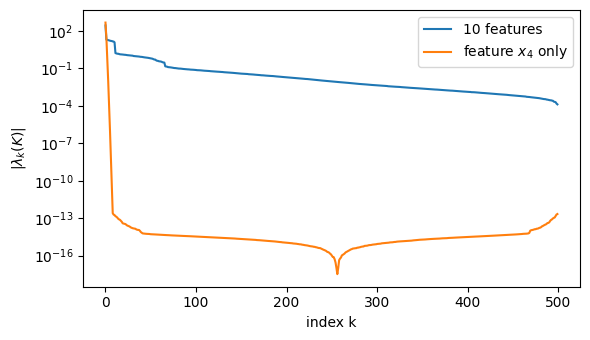

In [82]:
K1 = k_gauss(Xtr[:, [3]], Xtr[:, [3]], sigma)
for name, M in [("10 features", K), ("1 feature ", K1)]:
    ev = np.linalg.eigvalsh(M)
    try:
        sl.cholesky(M, lower=True); ok = "succeeds"
    except np.linalg.LinAlgError:
        ok = "FAILS"
    print(f"{name}: eigenvalues in [{ev[0]: .2e}, {ev[-1]:.1f}], cholesky {ok}")

plt.figure(figsize=(6, 3.5))
plt.semilogy(np.abs(np.linalg.eigvalsh(K))[::-1], label="10 features")
plt.semilogy(np.abs(np.linalg.eigvalsh(K1))[::-1], label="feature $x_4$ only")
plt.xlabel("index k"); plt.ylabel(r"$|\lambda_k(K)|$"); plt.legend(); plt.tight_layout(); plt.show()

**Your answer.**

Both predictions hold.

With 10 features the eigenvalues decay slowly, from 276.7 to $1.3\cdot10^{-4}$, all clearly positive, so `cholesky(K)` succeeds.

With one feature they drop to $\sim10^{-13}$ after probably 10 eigenvalues and the rest are rounding noise at $10^{-14}$-$10^{-16}$, about half of them negative, so `cholesky(K1)` fails. In exact arithmetic these eigenvalues are tiny and positive, but too small to survive rounding.

The dimension matters because on a line the points are very close compared with $\sigma$, so many rows of $K_1$ are nearly identical; in 10D the points are far apart and $K$ stays clearly positive definite.

Show that `cholesky(K1 + 1e-12 I)` succeeds. Then fit kernel ridge on the single feature with $\lambda = 10^{-12}$ and with $\lambda = 10^{-1}$. For each, report $\|\boldsymbol\alpha\|$, the validation MSE, and how much the validation predictions move when $\mathbf{y}$ is perturbed by noise of size $10^{-6}$ (seed below). Explain why the first success does **not** mean the regression problem is solved well.

In [83]:
sl.cholesky(K1 + 1e-12 * np.eye(len(K1)), lower=True)
print("cholesky(K1 + 1e-12 I) succeeds")
K1va = k_gauss(Xva[:, [3]], Xtr[:, [3]], sigma)
dy = 1e-6 * np.random.default_rng(0).standard_normal(len(ytr))
for lam in [1e-12, 1e-1]:
    # YOUR CODE HERE
    print('\nlambda = ', lam)
    alpha = krr_fit(K1, ytr, lam)
    alpha_prt = krr_fit(K1, ytr + dy, lam)
    result = krr_predict(K1va, alpha)
    result_prt = krr_predict(K1va, alpha_prt)
    print('alpha norm: ', np.linalg.norm(alpha))
    print('MSE: ', mse(result, yva))
    print('Move: ', np.abs(result_prt - result).max())

cholesky(K1 + 1e-12 I) succeeds

lambda =  1e-12
alpha norm:  91380215877555.11
MSE:  15.210804077082033
Move:  0.05078125

lambda =  0.1
alpha norm:  920.0653689878836
MSE:  15.364051747013896
Move:  7.218351072424412e-08


**Your answer.**

Cholesky succeeds because $\lambda=10^{-12}$ lifts the rounding noise above zero, but the matrix is still extremely ill-conditioned and alpha norm is $\|\alpha\|\approx9\cdot10^{13}$.

Many points on the line are almost identical, so fitting their small differences in $\mathbf{y}$ needs huge opposing weights ($9\cdot10^{13}$), and a $10^{-6}$ change in $\mathbf{y}$ moves the predictions by 0.05.

With $\lambda=10^{-1}$ the solution is stable ($\|\alpha\|\approx920$, movement $7\cdot10^{-8}$) at a similar MSE.

**(c)** *Predict, then compute.* For $\lambda = 10^{-8}, 10^{-7},\dots,10^{2}$, predict $\operatorname{cond}(K+\lambda I)$ for the ten-feature `K` from its eigenvalues alone. Then compute it with `np.linalg.cond` and compare.

**Your prediction** *(write it before running the next cell)*:

Adding $\lambda I$ shifts every eigenvalue by $\lambda$, so $\operatorname{cond}(K+\lambda I) = (\lambda_{\max}+\lambda)/(\lambda_{\min}+\lambda)$ with $\lambda_{\max}=276.7$, $\lambda_{\min}=1.32\cdot10^{-4}$ (from (a)).

For $\lambda\ll\lambda_{\min}$ ($10^{-8}$ to $10^{-6}$) it stays near $\operatorname{cond}(K)\approx2.1\cdot10^6$.

For $\lambda_{\min}\ll\lambda\ll\lambda_{\max}$ it is about $276.7/\lambda$, falling 10 times per step.

At $\lambda=10^2$ it approaches 1 (about 3.8).

The computed values should be pretty close, since `K` is well enough conditioned for its eigenvalues to be accurate.

In [84]:
ev = np.linalg.eigvalsh(K)
lams = 10.0 ** np.arange(-8, 3)
for lam in lams:
    # YOUR CODE HERE
    pred = (ev[-1] + lam) / (ev[0] + lam)
    print(f"lam = {lam:7.0e}: predicted {pred:.3e}, computed {np.linalg.cond(K + lam * np.eye(len(K))):.3e}")

lam =   1e-08: predicted 2.096e+06, computed 2.096e+06
lam =   1e-07: predicted 2.094e+06, computed 2.094e+06
lam =   1e-06: predicted 2.080e+06, computed 2.080e+06
lam =   1e-05: predicted 1.948e+06, computed 1.948e+06
lam =   1e-04: predicted 1.193e+06, computed 1.193e+06
lam =   1e-03: predicted 2.444e+05, computed 2.444e+05
lam =   1e-02: predicted 2.731e+04, computed 2.731e+04
lam =   1e-01: predicted 2.765e+03, computed 2.765e+03
lam =   1e+00: predicted 2.777e+02, computed 2.777e+02
lam =   1e+01: predicted 2.867e+01, computed 2.867e+01
lam =   1e+02: predicted 3.767e+00, computed 3.767e+00


**Your answer.**

The prediction $(\lambda_{\max}+\lambda)/(\lambda_{\min}+\lambda)$ matches `np.linalg.cond` to all printed digits, because adding $\lambda I$ shifts every eigenvalue by $\lambda$, and for a symmetric positive definite matrix the condition number is the ratio of the biggest and the smallest eigenvalues.

For $\lambda\ll\lambda_{\min}=1.3\cdot10^{-4}$ it stays at $\operatorname{cond}(K)\approx2.1\cdot10^6$.

For $\lambda_{\min}\ll\lambda\ll\lambda_{\max}$ it falls as $276.7/\lambda$, 10 times bigger per step.

At $\lambda=10^2$ it is about 3.8.

So $\lambda$ improves conditioning only once it exceeds the smallest eigenvalue.

**(d)** For the same values of $\lambda$, plot training and validation MSE (log scale in $\lambda$) and mark the $\lambda$ you would choose. Report the test MSE at that $\lambda$. In one paragraph, relate the left end of the plot to (c), and the right end to what ridge does to the coefficients.

chosen lam = 0.01; test MSE = 2.133  (noise variance is 1)


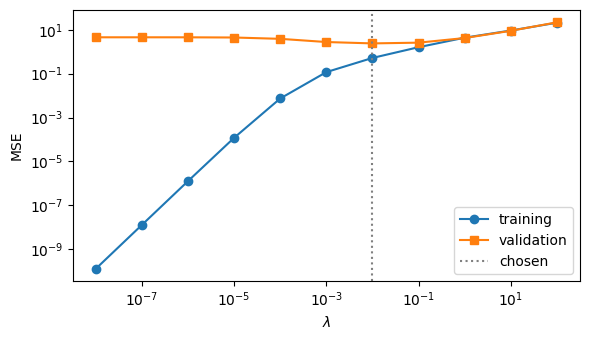

In [85]:
Kva = k_gauss(Xva, Xtr, sigma)
tr_err, va_err = [], []
for lam in lams:
    # YOUR CODE HERE
    alpha = krr_fit(K, ytr, lam)
    t_result = krr_predict(K, alpha)
    v_result = krr_predict(Kva, alpha)
    t_mse = mse(t_result, ytr)
    tr_err.append(t_mse)
    v_mse = mse(v_result, yva)
    va_err.append(v_mse)
best = lams[int(np.argmin(va_err))]
a = krr_fit(K, ytr, best)
print(f"chosen lam = {best:g}; test MSE = {mse(krr_predict(k_gauss(Xte, Xtr, sigma), a), yte):.3f}  (noise variance is 1)")
plt.figure(figsize=(6, 3.5))
plt.loglog(lams, tr_err, "o-", label="training"); plt.loglog(lams, va_err, "s-", label="validation")
plt.axvline(best, color="grey", ls=":", label="chosen")
plt.xlabel(r"$\lambda$"); plt.ylabel("MSE"); plt.legend(); plt.tight_layout(); plt.show()

**Your answer.**

The chosen $\lambda=10^{-2}$ gives test MSE 2.13.

At the left end the training MSE is tiny ($\sim10^{-10}$) but validation is about 5: the model tries to fit noice and overfits.

As in (c) for $\lambda<\lambda_{\min}=1.3\cdot10^{-4}$ adding $\lambda I$ barely changes `K`, so there is no real regularisation and the validation error stays flat.

At the right end ridge shrinks $\alpha$ towards zero, predictions approach the mean of $y$, and both errors rise to about 20: the model underfits.

---
## B4. Cost and scale

**(a)** *Predict, then measure.* Predict the slope of $\log(\text{time})$ against $\log n$ separately for **building** $K$ (with `k_gauss`) and for **fitting** (with `krr_fit`). Time both for $n = 500, 1000, 2000, 4000, 8000$, on fresh Friedman data with the same distribution, and fit the slopes from $n \ge 1000$. *The largest case needs about 2 GB of memory and a few seconds.*

**Your prediction** *(write it before running the next cell)*:

Building $K$ costs about $n^2p$ as in B2, so the slope should be about 2.

Fitting is a Cholesky of an $n\times n$ matrix, about $n^3/3$, so the slope should be about 3.

In [86]:
Xbig, ybig = make_friedman1(n_samples=8000, noise=1.0, random_state=1)
Xbig = (Xbig - Xbig.mean(axis=0)) / Xbig.std(axis=0)
ns = [500, 1000, 2000, 4000, 8000]
t_build, t_fit = [], []
for m in ns:
    t0 = time.perf_counter(); Km = k_gauss(Xbig[:m], Xbig[:m], sigma); t_build.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); krr_fit(Km, ybig[:m] - ybig[:m].mean(), 1e-2); t_fit.append(time.perf_counter() - t0)
    del Km
    print(f"n = {m:5d}: build {t_build[-1]:7.3f} s, fit {t_fit[-1]:7.3f} s")
sb = np.polyfit(np.log(ns[1:]), np.log(t_build[1:]), 1)[0]
sf = np.polyfit(np.log(ns[1:]), np.log(t_fit[1:]), 1)[0]
print(f"fitted slopes: build {sb:.2f}, fit {sf:.2f}")

n =   500: build   0.006 s, fit   0.119 s
n =  1000: build   0.059 s, fit   0.036 s
n =  2000: build   0.190 s, fit   0.153 s
n =  4000: build   0.468 s, fit   1.086 s
n =  8000: build   1.875 s, fit   8.813 s
fitted slopes: build 1.63, fit 2.67


**Your answer.**

Actual results build 1.63, fit 2.67 are bellow our predictions.

Time still grows much faster than linearly, but flops measure work, not speed: on larger matrices the computer calculates more eficiently, so it does more flops per second and the time grows less than the flop count.

Each size was also timed only once, so the slopes are rough estimates.

**(b)** At 8 bytes per entry, at what $n$ does $K$ alone fill 16 GB? Name one thing you would have to give up, or change, to fit kernel ridge on ten times that many points. Session 6 returns to this; a sentence is enough.

**Your answer.**

$K$ needs $8n^2$ bytes, so $8n^2 = 16\cdot10^9$ gives $n\approx45,000$ points.  

For ten times more points we would have to give up the exact $K$, and for example replace it with a low-rank approximation!

---
# Extension — attempt **at most one** in the whole lab

End your extension with a paragraph headed **Finding**: one claim you can defend at the defence, supported by a number in this notebook.

## E3. Gaussian-process regression is kernel ridge

A Gaussian process with kernel $k$ treats the values $f(\mathbf{x})$ as jointly Gaussian with mean 0 and covariance $k(\mathbf{x},\mathbf{x}')$. Observations are $y_i = f(\mathbf{x}_i) + \text{noise}$, with independent noise of variance $s^2$.

**(a)** Write down the joint covariance of $(\mathbf{y}, f(\mathbf{x}_*))$ for a test point $\mathbf{x}_*$. Use the conditional-Gaussian formula of Session 4.2 (frame `gauss-cond`: $\mathbf{x}_2\mid\mathbf{x}_1=\mathbf{a}$ has mean $\boldsymbol\mu_2 + \Sigma_{21}\Sigma_{11}^{-1}(\mathbf{a}-\boldsymbol\mu_1)$ and covariance $\Sigma/\Sigma_{11}$) to show that the posterior mean of $f(\mathbf{x}_*)$ equals the kernel ridge prediction with $\lambda = s^2$.

**Your answer.**

Let $\mathbf{k}_* = \big(k(\mathbf{x}_1,\mathbf{x}_*),\dots,k(\mathbf{x}_n,\mathbf{x}_*)\big)$ be the similarities of the test point to the training points. Both $\mathbf{y}$ and $f(\mathbf{x}_*)$ have mean 0, and their joint covariance is
$$\operatorname{Cov}\begin{pmatrix}\mathbf{y}\\ f(\mathbf{x}_*)\end{pmatrix} = \begin{pmatrix} K+s^2I & \mathbf{k}_*\\ \mathbf{k}_*^\top & k(\mathbf{x}_*,\mathbf{x}_*)\end{pmatrix}.$$


The noise is independent of $f$, so it only adds $s^2$ to the diagonal of $\operatorname{Cov}(\mathbf{y})$.

By the conditional-Gaussian formula with $\mathbf{x}_1=\mathbf{y}$, $\mathbf{x}_2=f(\mathbf{x}_*)$, $\Sigma_{11}=K+s^2I$ and $\Sigma_{21}=\mathbf{k}_*^\top$, the posterior mean is


$$\mathbf{k}_*^\top(K+s^2I)^{-1}\mathbf{y} = \mathbf{k}_*^\top\boldsymbol\alpha = \sum_i \alpha_i\,k(\mathbf{x}_i,\mathbf{x}_*), \qquad \text{where } (K+s^2I)\boldsymbol\alpha=\mathbf{y}.$$


So for each training point, we multiply its weight by how similar it is to the new point, and add everything up and this is exactly the kernel ridge prediction with $\lambda=s^2$.

**(b)** Implement `gp_posterior(Xtr, ytr, Xte, sigma, s2)` for the Gaussian kernel, returning the posterior mean and variance at each test point. Use one Cholesky factor of $K+s^2I$ and **one triangular solve** for all the variances (no inverse). **Check** the mean against your `krr_fit`/`krr_predict`, and both outputs against `GaussianProcessRegressor` with the kernel fixed.

The data below are one-dimensional, with a deliberate gap in $[0.4, 0.6]$.

In [87]:
rng = np.random.default_rng(7)
x1 = np.concatenate([rng.uniform(0, 0.4, 20), rng.uniform(0.6, 1.0, 20)])[:, None]
y1 = np.sin(2 * np.pi * x1[:, 0]) + 0.5 * x1[:, 0] + 0.2 * rng.standard_normal(40)
xg = np.linspace(-0.2, 1.2, 300)[:, None]
sig_gp, s2 = 0.1, 0.2 ** 2

def gp_posterior(Xtr, ytr, Xte, sigma, s2):
    # YOUR CODE HERE
    K = k_gauss(Xtr, Xtr, sigma)
    Ks = k_gauss(Xtr, Xte, sigma)
    A = K + s2 * np.eye(len(K))
    factor = sl.cho_factor(A, lower=True)
    alpha = sl.cho_solve(factor, ytr)
    mean = Ks.T @ alpha
    v = sl.solve_triangular(factor[0], Ks, lower=True)
    var = 1 - (v ** 2).sum(axis=0)
    return mean, var

mean, var = gp_posterior(x1, y1, xg, sig_gp, s2)
# check
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
gpr = GaussianProcessRegressor(kernel=RBF(length_scale=sig_gp), alpha=s2, optimizer=None).fit(x1, y1)
m_ref, sd_ref = gpr.predict(xg, return_std=True)
assert np.allclose(mean, krr_predict(k_gauss(xg, x1, sig_gp), krr_fit(k_gauss(x1, x1, sig_gp), y1, s2)))
assert np.allclose(mean, m_ref) and np.allclose(np.sqrt(np.clip(var, 0, None)), sd_ref, atol=1e-6)
print("posterior mean = kernel ridge prediction; matches sklearn")

posterior mean = kernel ridge prediction; matches sklearn


**(c)** Plot the posterior mean with a band of $\pm2$ posterior standard deviations, together with the data. Explain where the band is wide and why, using the Schur-complement reading of the conditional covariance.

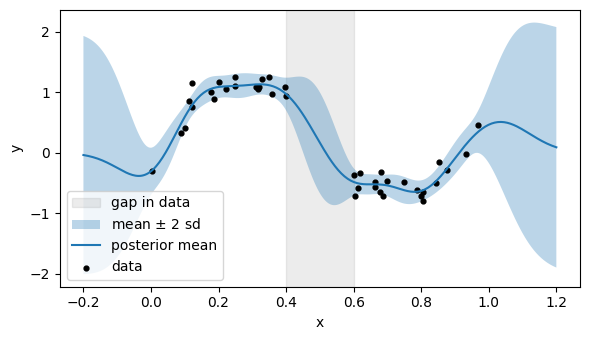

max sd near data: 0.102
max sd in gap:    0.417
sd at x = -0.2:   0.985


In [88]:
# YOUR CODE HERE
sd = np.sqrt(var)
x = xg[:, 0]
plt.figure(figsize=(6, 3.5))
plt.axvspan(0.4, 0.6, color="grey", alpha=0.15, label="gap in data")
plt.fill_between(x, mean - 2 * sd, mean + 2 * sd, alpha=0.3, label=r"mean $\pm$ 2 sd")
plt.plot(x, mean, label="posterior mean")
plt.scatter(x1[:, 0], y1, s=12, color="k", label="data")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.tight_layout(); plt.show()

near = (x > 0.1) & (x < 0.3)
gap = (x > 0.4) & (x < 0.6)
print(f'max sd near data: {sd[near].max():.3f}')
print(f'max sd in gap:    {sd[gap].max():.3f}')
print(f'sd at x = -0.2:   {sd[0]:.3f}')

**Your answer.**

The band is narrow near the data (sd $≤ 0.10$), wider in the gap (0.42) and very wide outside the data (0.985 at $x=-0.2$).

The variance is the Schur complement $k(x_*,x_*) - \mathbf{k}_*^\top(K+s^2I)^{-1}\mathbf{k}_*$: complete uncertainty minus what the data explains. Near training points $\mathbf{k}_*$ is large, so the variance is small; far from them $\mathbf{k}_*\approx0$, so it returns to almost full uncertaincy.

**Finding.** GP regression gives the same predictions as kernel ridge with $\lambda=s^2$, but also shows where we can trust the result: the posterior sd is 0.10 near the data, 0.42 in the gap and 0.985 far outside, so uncertainty grows with distance from the training points.

---
**Before you submit:** run `Kernel → Restart & Run All`, check that every written answer is filled in, and make sure your extension (if any) ends with a **Finding**.